# Transmon from physical parameters

Inputs: total shunt capacitance $C_\Sigma$, junction critical current density $J_c$, junction area $A$.

- $I_c = J_c A$
- $E_J = \dfrac{\Phi_0 I_c}{2\pi} = \dfrac{\hbar I_c}{2e}$
- $E_C = \dfrac{e^2}{2 C_\Sigma}$

Hamiltonian: $H = 4E_C(\hat n - n_g)^2 - E_J\cos\hat\varphi$

In [1]:
import numpy as np
import scqubits as scq
import matplotlib.pyplot as plt
from scipy.constants import e, h, hbar

## Physical inputs

In [2]:
C_sigma = 121.3e-15      # total capacitance [F]
Jc      = 0.5           # critical current density [uA/um^2]  (0.5 uA/um^2 = 50 A/cm^2)
jj_w    = 0.42           # junction width  [um]
jj_l    = 0.2           # junction length [um]
ng      = 0.0           # offset charge
ncut    = 50            # charge-basis cutoff

## Convert to $E_J$, $E_C$ (in GHz, i.e. $E/h$)

In [3]:
def transmon_params(C_sigma, Jc_uA_um2, area_um2):
    Ic = Jc_uA_um2 * 1e-6 * area_um2          # [A]
    EJ = hbar * Ic / (2 * e) / h / 1e9         # [GHz]
    EC = e**2 / (2 * C_sigma) / h / 1e9        # [GHz]
    return Ic, EJ, EC

area = jj_w * jj_l
Ic, EJ, EC = transmon_params(C_sigma, Jc, area)
LJ = hbar / (2 * e * Ic)

print(f"Junction area : {area:.4f} um^2")
print(f"Ic            : {Ic*1e9:.2f} nA")
print(f"LJ            : {LJ*1e9:.2f} nH")
print(f"EJ/h          : {EJ:.3f} GHz")
print(f"EC/h          : {EC*1e3:.1f} MHz")
print(f"EJ/EC         : {EJ/EC:.1f}")
print(f"Approx f01    : {np.sqrt(8*EJ*EC) - EC:.3f} GHz   (sqrt(8 EJ EC) - EC)")

Junction area : 0.0840 um^2
Ic            : 42.00 nA
LJ            : 7.84 nH
EJ/h          : 20.861 GHz
EC/h          : 159.7 MHz
EJ/EC         : 130.6
Approx f01    : 5.003 GHz   (sqrt(8 EJ EC) - EC)


## Build the transmon and get eigenenergies

In [4]:
tmon = scq.Transmon(EJ=EJ, EC=EC, ng=ng, ncut=ncut, truncated_dim=10)

evals = tmon.eigenvals(evals_count=6)
E = evals - evals[0]
f01, f12 = E[1], E[2] - E[1]
print(f"f01           : {f01:.4f} GHz")
print(f"f12           : {f12:.4f} GHz")
print(f"anharmonicity : {(f12 - f01)*1e3:.1f} MHz   (≈ -EC = {-EC*1e3:.1f} MHz)")
for i, Ei in enumerate(E):
    print(f"  E{i} - E0 = {Ei:8.4f} GHz")

f01           : 4.9973 GHz
f12           : 4.8246 GHz
anharmonicity : -172.7 MHz   (≈ -EC = -159.7 MHz)
  E0 - E0 =   0.0000 GHz
  E1 - E0 =   4.9973 GHz
  E2 - E0 =   9.8218 GHz
  E3 - E0 =  14.4630 GHz
  E4 - E0 =  18.9077 GHz
  E5 - E0 =  23.1390 GHz


## Wavefunctions in the cosine potential

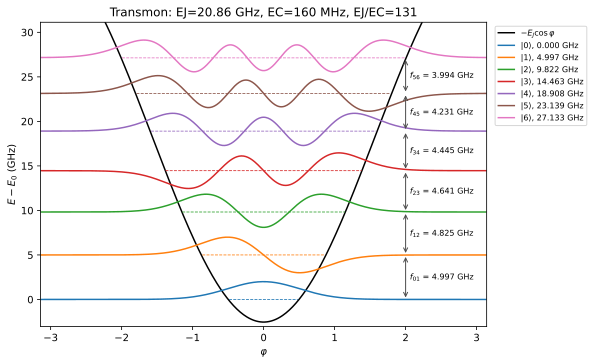

In [5]:
def plot_levels_in_well(qubit, n_levels=7, title=None):
    # works for scq.Transmon and scq.TunableTransmon (qubit.EJ is the effective, flux-dependent EJ)
    EJ_eff = qubit.EJ
    phi_grid = scq.Grid1d(-np.pi, np.pi, 401)
    evals_, evecs_ = qubit.eigensys(evals_count=n_levels)
    E0 = evals_[0]
    scale = 0.4 * (evals_[1] - evals_[0])   # visual amplitude of wavefunctions

    fig, ax = plt.subplots(figsize=(8, 5.5))
    phi = phi_grid.make_linspace()
    V = -EJ_eff * np.cos(phi) - E0
    ax.plot(phi, V, 'k', lw=1.5, label=r'$-E_J\cos\varphi$')
    for k in range(n_levels):
        wf = qubit.wavefunction(esys=(evals_, evecs_), which=k, phi_grid=phi_grid)
        amp = wf.amplitudes.real
        amp = amp / np.max(np.abs(amp)) * np.sign(amp[np.argmax(np.abs(amp))])  # normalize, fix sign
        Ek = evals_[k] - E0
        in_well = V <= Ek                     # level line only inside the well
        ax.plot(phi[in_well], np.full(in_well.sum(), Ek), color=f'C{k}', lw=0.8, ls='--')
        ax.plot(wf.basis_labels, Ek + scale * amp, color=f'C{k}', label=fr'$|{k}\rangle$, {Ek:.3f} GHz')

    # transition arrows |k> -> |k+1>, labeled with the transition frequency
    x0 = 2.0
    for k in range(n_levels - 1):
        lo, hi = evals_[k] - E0, evals_[k + 1] - E0
        ax.annotate('', xy=(x0, hi), xytext=(x0, lo), arrowprops=dict(arrowstyle='<->', color='0.3', lw=1))
        ax.text(x0 + 0.06, (lo + hi) / 2, fr'$f_{{{k}{k+1}}}$ = {hi - lo:.3f} GHz', va='center', fontsize=8)

    ax.set_xlabel(r'$\varphi$')
    ax.set_ylabel(r'$E - E_0$ (GHz)')
    ax.set_ylim(-EJ_eff - E0 - 0.5, (evals_[-1] - E0) + 2 * scale)
    ax.set_xlim(-np.pi, np.pi)
    ax.set_title(title or f'Transmon: EJ={EJ_eff:.2f} GHz, EC={qubit.EC*1e3:.0f} MHz, EJ/EC={EJ_eff/qubit.EC:.0f}')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.show()

plot_levels_in_well(tmon, n_levels=7)

## Charge dispersion: eigenenergies vs. $n_g$

At large $E_J/E_C$ the levels are nearly flat in $n_g$ — that's the transmon's protection. Drop `jj_w`/`jj_l` or raise `EC` (smaller `C_sigma`) to see the bands bend.

Spectral data:   0%|          | 0/201 [00:00<?, ?it/s]

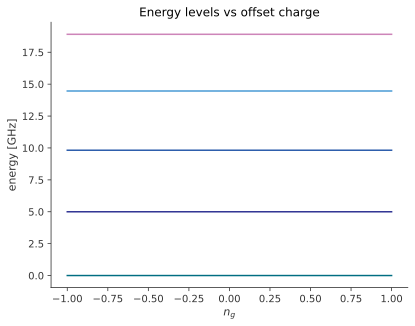

Spectral data:   0%|          | 0/201 [00:00<?, ?it/s]

charge dispersion level 0:      0.000 kHz
charge dispersion level 1:      0.000 kHz
charge dispersion level 2:      0.006 kHz
charge dispersion level 3:      0.196 kHz


In [6]:
ng_list = np.linspace(-1, 1, 201)
fig, ax = tmon.plot_evals_vs_paramvals('ng', ng_list, evals_count=5, subtract_ground=True)
ax.set_title('Energy levels vs offset charge')
plt.show()

# charge dispersion of each level: max - min over ng
spec = tmon.get_spectrum_vs_paramvals('ng', ng_list, evals_count=4, subtract_ground=False)
disp = spec.energy_table.max(axis=0) - spec.energy_table.min(axis=0)
for k, d in enumerate(disp):
    print(f"charge dispersion level {k}: {d*1e6:10.3f} kHz")
tmon.ng = ng

## Flux-tunable transmon (DC SQUID)

Replace the single junction with two junctions in parallel (a SQUID). The loop phase constraint $\varphi_1 - \varphi_2 = 2\pi\Phi/\Phi_0$ lets the pair act as **one effective junction** with a flux-dependent Josephson energy:

$$E_J(\Phi) = E_{J\Sigma}\,\left|\cos\frac{\pi\Phi}{\Phi_0}\right|\sqrt{1 + d^2\tan^2\frac{\pi\Phi}{\Phi_0}},\qquad E_{J\Sigma} = E_{J1}+E_{J2},\quad d = \frac{E_{J2}-E_{J1}}{E_{J1}+E_{J2}}$$

The Josephson inductance is $L_J = \dfrac{\Phi_0}{2\pi I_c} = \dfrac{(\hbar/2e)^2}{E_J}$, so it scales as $1/E_J$:

| flux | $E_J$ | $L_J$ | $f_{01} \approx \sqrt{8E_JE_C}-E_C$ |
|---|---|---|---|
| $\Phi = 0$ (upper sweet spot) | **max** $=E_{J\Sigma}$ | **min** | **max** |
| $\Phi = \Phi_0/2$ (lower sweet spot) | **min** $= \lvert d\rvert E_{J\Sigma}$ | **max** (→ ∞ if $d=0$) | **min** |

At both points $\partial f/\partial\Phi = 0$, so the qubit is first-order insensitive to flux noise there; zero flux is the usual operating point. A symmetric SQUID ($d=0$) tunes all the way to $E_J=0$; an asymmetric one has a limited tuning range but smaller flux sensitivity in between.

In [10]:
# SQUID junctions (same Jc and C_sigma as above). Set them equal for a symmetric SQUID.
jj1_w, jj1_l = 0.42, 0.2   # [um]
jj2_w, jj2_l = 0.42, 0.2   # [um]
flux_op      = 0.0         # operating flux bias [Phi0]

Ic1, EJ1, _ = transmon_params(C_sigma, Jc, jj1_w * jj1_l)
Ic2, EJ2, _ = transmon_params(C_sigma, Jc, jj2_w * jj2_l)
EJmax = EJ1 + EJ2
d = (EJ2 - EJ1) / EJmax

ttmon = scq.TunableTransmon(EJmax=EJmax, EC=EC, d=d, flux=flux_op, ng=ng, ncut=ncut, truncated_dim=10)

def LJ_from_EJ(EJ_GHz):
    # L_J = (hbar/2e)^2 / E_J
    return (hbar / (2 * e))**2 / (EJ_GHz * 1e9 * h)

print(f"EJ1, EJ2      : {EJ1:.3f}, {EJ2:.3f} GHz")
print(f"EJmax = EJ1+EJ2 : {EJmax:.3f} GHz,  asymmetry d = {d:.3f}")
print(f"EJmin = |d| EJmax : {abs(d)*EJmax:.3f} GHz")
print(f"LJ at 0 flux  : {LJ_from_EJ(EJmax)*1e9:.2f} nH   (minimum)")
print(f"LJ at Phi0/2  : " + (f"{LJ_from_EJ(abs(d)*EJmax)*1e9:.2f} nH   (maximum)" if d != 0 else "inf   (symmetric SQUID)"))

EJ1, EJ2      : 20.861, 20.861 GHz
EJmax = EJ1+EJ2 : 41.721 GHz,  asymmetry d = 0.000
EJmin = |d| EJmax : 0.000 GHz
LJ at 0 flux  : 3.92 nH   (minimum)
LJ at Phi0/2  : inf   (symmetric SQUID)


Spectral data:   0%|          | 0/401 [00:00<?, ?it/s]

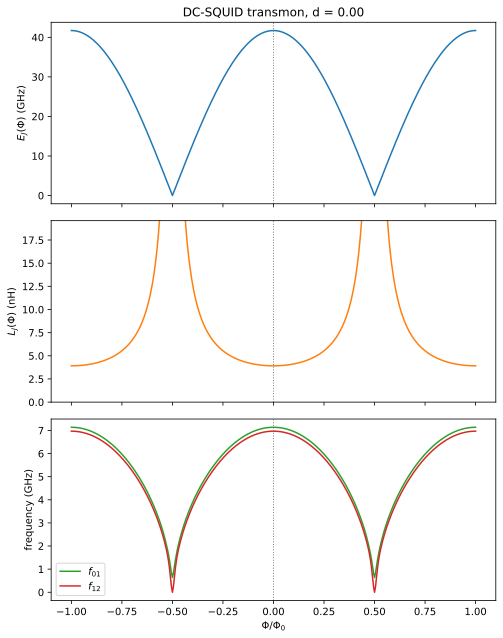

In [11]:
flux_list = np.linspace(-1, 1, 401)
spec = ttmon.get_spectrum_vs_paramvals('flux', flux_list, evals_count=4, subtract_ground=True)
f01_flux = spec.energy_table[:, 1]
f12_flux = spec.energy_table[:, 2] - spec.energy_table[:, 1]
EJ_flux = EJmax * np.sqrt(np.cos(np.pi * flux_list)**2 + d**2 * np.sin(np.pi * flux_list)**2)
with np.errstate(divide='ignore'):
    LJ_flux = LJ_from_EJ(EJ_flux) * 1e9   # [nH]

fig, axs = plt.subplots(3, 1, figsize=(7, 9), sharex=True)
axs[0].plot(flux_list, EJ_flux); axs[0].set_ylabel(r'$E_J(\Phi)$ (GHz)')
axs[1].plot(flux_list, LJ_flux, 'C1'); axs[1].set_ylabel(r'$L_J(\Phi)$ (nH)')
axs[1].set_ylim(0, 5 * LJ_from_EJ(EJmax) * 1e9)
axs[2].plot(flux_list, f01_flux, 'C2', label=r'$f_{01}$')
axs[2].plot(flux_list, f12_flux, 'C3', label=r'$f_{12}$')
axs[2].set_ylabel('frequency (GHz)'); axs[2].set_xlabel(r'$\Phi/\Phi_0$'); axs[2].legend()
for a in axs:
    a.axvline(flux_op, color='gray', ls=':', lw=1)
axs[0].set_title(f'DC-SQUID transmon, d = {d:.2f}')
plt.tight_layout()
plt.show()

Levels and wavefunctions at the operating flux (change `flux_op` above, e.g. 0.3, to see the well get shallower and the levels compress):

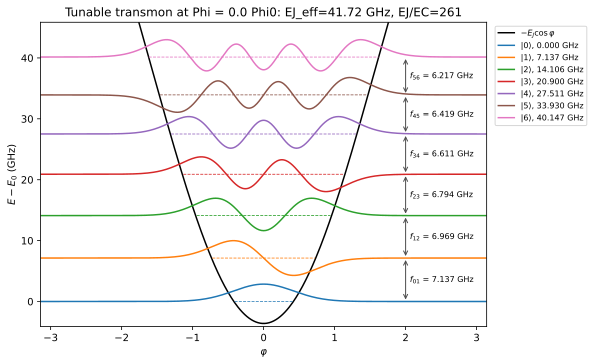

In [12]:
ttmon.flux = flux_op
plot_levels_in_well(ttmon, n_levels=7,
                    title=f'Tunable transmon at Phi = {flux_op} Phi0: EJ_eff={ttmon.EJ:.2f} GHz, EJ/EC={ttmon.EJ/EC:.0f}')